# Step 1 (gimbal phase 1): Stage A, the frictionless free fall

## 1. Where we start, what we want, what we get

| | |
|---|---|
| **We have (known inputs)** | $m,\ L,\ r,\ g,\ \Delta t$; start tilt $\theta_0=5^\circ$; lean direction $\varphi_0=45^\circ$; start at rest |
| **Unknown** | the motion after release: $q_1(t),\ q_2(t),\ \dot q_1(t),\ \dot q_2(t)$ |
| **Set to 0 (switched off)** | motor torque $\mathbf u=0$, viscous damping $b=0$, Coulomb friction $c=0$, noise $=0$ |
| **What we do** | write the equations of motion, turn them into $y'=f(y)$, step forward with RK4 |
| **What we get** | arrays of angles, rates and energy after each step, until the tip passes horizontal |
| **Pass rule** | MuJoCo (frictionless, same start): max abs angle error $\le 10^{-6}$ rad |

## 2. The equations

**1.1 Constants** (derived from the known inputs)

$$I_p=\frac{mL^2}{3},\qquad I_{zz}=\frac{mr^2}{2},\qquad U_0=\frac{mgL}{2}$$

| Symbol | Meaning | Unit | Status | Code name |
|---|---|---|---|---|
| $m, L, r, g$ | mass, length, radius, gravity | kg, m, m, m/s² | known input | `rod_mass`, `rod_length`, `rod_radius`, `gravity` |
| $I_p$ | inertia about the pivot | kg·m² | output (1/3) | `pivot_inertia` |
| $I_{zz}$ | inertia about the long axis | kg·m² | output (2e-4) | `axial_inertia` |
| $U_0$ | gravity energy scale | J | output (4.905) | `gravity_energy_scale` |

**1.2 Start angles from tilt and direction.** The rod axis is $u=(\sin q_2,\ -\sin q_1\cos q_2,\ \cos q_1\cos q_2)$. It must equal $(\sin\theta_0\cos\varphi_0,\ \sin\theta_0\sin\varphi_0,\ \cos\theta_0)$. Solving:

$$q_2=\arcsin(\sin\theta_0\cos\varphi_0),\qquad q_1=\arcsin\!\left(\frac{-\sin\theta_0\sin\varphi_0}{\cos q_2}\right)$$

| Symbol | Meaning | Unit | Status | Code name |
|---|---|---|---|---|
| $\theta_0,\ \varphi_0$ | start tilt, lean direction | rad | known input (5°, 45°) | `START_TILT_DEG`, `LEAN_DIRECTION_DEG` |
| $q_1,\ q_2$ at $t=0$ | start angles | rad | output | `start_angles` |
| $\dot q_1,\ \dot q_2$ at $t=0$ | start rates | rad/s | known input (0, 0) | `start_rates` |

**1.3 Tip height** (used only to stop the run when the rod passes horizontal)

$$z_{\text{tip}}=L\cos q_1\cos q_2$$

**1.4 Mass matrix.** It is diagonal because the two hinge axes are perpendicular to each other and the rod is symmetric.

$$M(q)=\begin{pmatrix}M_{11}&0\\0&I_p\end{pmatrix},\qquad M_{11}=I_p\cos^2 q_2+I_{zz}\sin^2 q_2$$

**1.5 Velocity coupling torques** (zero when the rod is at rest)

$$h_1=(I_{zz}-I_p)\sin 2q_2\ \dot q_1\dot q_2,\qquad h_2=-\tfrac12(I_{zz}-I_p)\sin 2q_2\ \dot q_1^{2}$$

**1.6 Gravity torques.** Potential energy is $U=U_0\cos q_1\cos q_2$ (zero at pivot height). The gravity torque vector is its gradient:

$$g_1=\frac{\partial U}{\partial q_1}=-U_0\sin q_1\cos q_2,\qquad g_2=\frac{\partial U}{\partial q_2}=-U_0\cos q_1\sin q_2$$

**1.7 Equation of motion** (Euler-Lagrange, derived in E1 to E4)

$$M(q)\,\ddot q+\mathbf h(q,\dot q)+\mathbf g(q)=\boldsymbol\tau,\qquad \boldsymbol\tau=\mathbf u-b\,\dot q-c\,s(\dot q)$$

In step 1: $\mathbf u=0,\ b=0,\ c=0$, so $\boldsymbol\tau=0$. Because $M$ is diagonal, solving for the accelerations is two divisions:

$$\ddot q_i=\frac{\tau_i-h_i-g_i}{M_{ii}},\qquad i=1,2$$

| Symbol | Meaning | Unit | Status | Code name |
|---|---|---|---|---|
| $\ddot q_i$ | hinge acceleration | rad/s² | output (this is what the equation gives us) | `angular_acceleration` |
| $\boldsymbol\tau$ | total torque on the hinges | N·m | **set to 0** | `motor_torque` (zeros placeholder) |
| $\mathbf h,\ \mathbf g$ | from 1.5, 1.6 | N·m | output | `velocity_bias_torque`, `gravity_torque` |

**1.8 State form.** RK4 integrates a first-order system, so we stack angles and rates:

$$y=\begin{pmatrix}q_1\\q_2\\\dot q_1\\\dot q_2\end{pmatrix},\qquad y'=f(y,\boldsymbol\tau)=\begin{pmatrix}\dot q_1\\\dot q_2\\\ddot q_1\\\ddot q_2\end{pmatrix}$$

**1.9 RK4 step** (the torque $\boldsymbol\tau$ is held constant across the four slope samples)

$$k_1=f(y_k),\quad k_2=f\!\left(y_k+\tfrac{\Delta t}{2}k_1\right),\quad k_3=f\!\left(y_k+\tfrac{\Delta t}{2}k_2\right),\quad k_4=f(y_k+\Delta t\,k_3)$$

$$y_{k+1}=y_k+\frac{\Delta t}{6}\,(k_1+2k_2+2k_3+k_4)$$

**1.10 Energy** (conserved when $\boldsymbol\tau=0$)

$$E=\tfrac12\left(M_{11}\dot q_1^{2}+I_p\dot q_2^{2}\right)+U_0\cos q_1\cos q_2$$

## 3. Plug in, get out

```
known inputs (m, L, r, g, dt, 5 deg, 45 deg)
   -> 1.1 constants (I_p, I_zz, U0)
   -> 1.2 start state y0 = (q1, q2, 0, 0)
   -> repeat: 1.4 M, 1.5 h, 1.6 g -> 1.7 q_ddot -> 1.8 f(y) -> 1.9 RK4 -> y_(k+1)
   -> store y_(k+1) and E  (row k is the state at t = (k+1) dt)
   -> stop when z_tip < 0
```

## 4. Conclusion

At the end you hold the frictionless trajectory of the rod as arrays. Checks:

| Check | Expected |
|---|---|
| $M_{11}$ at $q_2=0.8$ | 0.161903 kg·m² |
| $\mathbf h+\mathbf g$ at $q=(0.5,0.8),\ \dot q=(1,2)$ | $(-2.30435,\ -2.92139)$ N·m, equal to MuJoCo `qfrc_bias` |
| start angles | $(-0.0618,\ +0.0617)$ rad |
| first acceleration at rest | $(-0.910,\ +0.905)$ rad/s² |
| max angle error vs MuJoCo | $\le 10^{-6}$ rad |
| energy drift in the fall | tiny (my test run: about $10^{-10}$ J) |


## Code

Names in the code follow the `Code name` columns of the tables above.

In [1]:
import os
from datetime import datetime

import numpy as np  # type: ignore
import matplotlib.pyplot as plt  # type: ignore

from mujoco_reference import run_mujoco, mujoco_mass_and_bias  # reference only: the hand code never calls MuJoCo

NOTEBOOK_NAME = "1_frictionless_fall"
# results of this notebook go to sim2real/modeling/result/<notebook name>/
RESULT_DIR = os.path.abspath(os.path.join(os.getcwd(), "..", "result", NOTEBOOK_NAME))
os.makedirs(RESULT_DIR, exist_ok=True)
TIMESTAMP = datetime.now().strftime("%Y%m%d_%H%M%S")
print("Saving results to:", RESULT_DIR)


Saving results to: /tmp/claude-0/-home-claude/bd8fb49c-ee3f-59e8-a19e-bae64cb3f70a/scratchpad/repo/sim2real/modeling/result/1_frictionless_fall


In [2]:
# ─────────────────────────────────────────────
# STEP 1: constants (equation 1.1)
# What we have: rod mass, length, radius, gravity, time step (foundational)
# What we want: pivot_inertia, axial_inertia, gravity_energy_scale (derived)
# Why: these three numbers are all the inertia and gravity terms need
# Formulas:
#   pivot_inertia = m L^2 / 3   (kg*m^2)
#   axial_inertia = m r^2 / 2   (kg*m^2)
#   gravity_energy_scale = m g L / 2   (J)
# ─────────────────────────────────────────────
gravity = 9.81  # m/s^2, foundational
rod_length = 1.0  # m, foundational
rod_mass = 1.0  # kg, foundational
rod_radius = 0.02  # m, foundational
time_step = 0.001  # s, foundational (same as MuJoCo)

pivot_inertia = rod_mass * rod_length**2 / 3  # kg*m^2, derived
axial_inertia = rod_mass * rod_radius**2 / 2  # kg*m^2, derived
gravity_energy_scale = rod_mass * gravity * rod_length / 2  # J, derived
print(f"pivot_inertia = {pivot_inertia:.5f} kg*m^2, axial_inertia = {axial_inertia:.1e} kg*m^2, gravity_energy_scale = {gravity_energy_scale:.4f} J")

START_TILT_DEG = 5  # deg, foundational test case
LEAN_DIRECTION_DEG = 45  # deg, 0 = toward +x, 90 = toward +y


pivot_inertia = 0.33333 kg*m^2, axial_inertia = 2.0e-04 kg*m^2, gravity_energy_scale = 4.9050 J


In [3]:
# ─────────────────────────────────────────────
# STEP 2: start angles (equation 1.2)
# What we have: start tilt and lean direction (5 and 45 degrees), start at rest
# What we want: start_angles = (outer_angle, inner_angle) in rad
# Why: the equations use hinge angles, the test case is given as tilt and direction
# Formulas:
#   inner_angle = arcsin(sin(tilt) cos(direction))
#   outer_angle = arcsin(-sin(tilt) sin(direction) / cos(inner_angle))
# ─────────────────────────────────────────────


def start_angles_from_tilt(tilt_deg, direction_deg):
    tilt = np.deg2rad(tilt_deg)
    direction = np.deg2rad(direction_deg)
    inner_angle = np.arcsin(np.sin(tilt) * np.cos(direction))
    outer_angle = np.arcsin(-np.sin(tilt) * np.sin(direction) / np.cos(inner_angle))
    return np.array([outer_angle, inner_angle])


start_angles = start_angles_from_tilt(START_TILT_DEG, LEAN_DIRECTION_DEG)  # rad
start_rates = np.zeros(2)  # rad/s, released at rest
print("start_angles =", start_angles, "rad   (expect about -0.0618, +0.0617)")


start_angles = [-0.06178509  0.06166749] rad   (expect about -0.0618, +0.0617)


In [4]:
# ─────────────────────────────────────────────
# STEP 3: physics (equations 1.3 to 1.7)
# What we have: angles and rates of the two hinges, the torque on them
# What we want: angular_acceleration (rad/s^2)
# Why: this is the physics: M q_ddot + h + g = torque
# Formulas:
#   tip_height = L cos(outer) cos(inner)
#   M = diag(M11, I_p),  M11 = I_p cos^2(inner) + I_zz sin^2(inner)
#   h1 =  (I_zz - I_p) sin(2 inner) outer_rate inner_rate;  h2 = -0.5 (I_zz - I_p) sin(2 inner) outer_rate^2
#   g1 = -U0 sin(outer) cos(inner);  g2 = -U0 cos(outer) sin(inner)
#   q_ddot = (torque - h - g) / M   (M is diagonal)
# ─────────────────────────────────────────────


def tip_height(angles):
    outer_angle, inner_angle = angles
    return rod_length * np.cos(outer_angle) * np.cos(inner_angle)  # m


def mass_matrix_diagonal(angles):
    inner_angle = angles[1]
    outer_inertia = pivot_inertia * np.cos(inner_angle) ** 2 + axial_inertia * np.sin(inner_angle) ** 2  # M11
    return np.array([outer_inertia, pivot_inertia])  # kg*m^2


def velocity_bias_torque(angles, rates):
    outer_rate, inner_rate = rates
    sin_two_inner = np.sin(2.0 * angles[1])
    return np.array([
        (axial_inertia - pivot_inertia) * sin_two_inner * outer_rate * inner_rate,
        -0.5 * (axial_inertia - pivot_inertia) * sin_two_inner * outer_rate**2,
    ])  # N*m


def gravity_torque(angles):
    outer_angle, inner_angle = angles
    return np.array([
        -gravity_energy_scale * np.sin(outer_angle) * np.cos(inner_angle),
        -gravity_energy_scale * np.cos(outer_angle) * np.sin(inner_angle),
    ])  # N*m


def angular_acceleration(angles, rates, motor_torque):
    total_torque = motor_torque
    return (total_torque - velocity_bias_torque(angles, rates) - gravity_torque(angles)) / mass_matrix_diagonal(angles)  # rad/s^2


In [5]:
# ─────────────────────────────────────────────
# STEP 4: state form, RK4 and energy (equations 1.8 to 1.10)
# What we have: the acceleration function and the state (outer_angle, inner_angle, outer_rate, inner_rate)
# What we want: the state one time step later, and the energy
# Why: RK4 turns y' = f(y) into numbers; energy is the check that nothing is leaking
# Formulas:
#   f(y) = (rates, angular_acceleration)
#   k1 = f(y); k2 = f(y + dt/2 k1); k3 = f(y + dt/2 k2); k4 = f(y + dt k3)
#   y_next = y + dt/6 (k1 + 2 k2 + 2 k3 + k4)
#   E = 0.5 (M11 outer_rate^2 + I_p inner_rate^2) + U0 cos(outer) cos(inner)
# ─────────────────────────────────────────────


def state_derivative(state, motor_torque):
    angles, rates = state[:2], state[2:]
    return np.concatenate([rates, angular_acceleration(angles, rates, motor_torque)])


def rk4_step(state, motor_torque, time_step):
    # motor_torque is held constant over all four stages, like a MuJoCo control input
    slope_1 = state_derivative(state, motor_torque)
    slope_2 = state_derivative(state + 0.5 * time_step * slope_1, motor_torque)
    slope_3 = state_derivative(state + 0.5 * time_step * slope_2, motor_torque)
    slope_4 = state_derivative(state + time_step * slope_3, motor_torque)
    return state + time_step / 6.0 * (slope_1 + 2.0 * slope_2 + 2.0 * slope_3 + slope_4)


def total_energy(state):
    angles, rates = state[:2], state[2:]
    mass_diagonal = mass_matrix_diagonal(angles)
    kinetic_energy = 0.5 * np.sum(mass_diagonal * rates**2)
    potential_energy = gravity_energy_scale * np.cos(angles[0]) * np.cos(angles[1])
    return kinetic_energy + potential_energy  # J


In [6]:
# ─────────────────────────────────────────────
# STEP 5: run the fall, state saved AFTER each step
# What we have: start state, number of steps, friction settings
# What we want: angle, rate and energy logs (row k is the state at t = (k + 1) * time_step)
# Why: same logging as MuJoCo, so rows compare index to index (equation 4.1)
# ─────────────────────────────────────────────


def simulate(start_angles, start_rates, n_steps, stop_below_horizontal=False):
    state = np.concatenate([start_angles, start_rates])
    motor_torque = np.zeros(2)  # placeholder, motors off in steps 1 to 4
    angle_log, rate_log, energy_log = [], [], []
    for step_index in range(n_steps):
        state = rk4_step(state, motor_torque, time_step)
        angle_log.append(state[:2].copy())
        rate_log.append(state[2:].copy())
        energy_log.append(total_energy(state))
        if stop_below_horizontal and tip_height(state[:2]) < 0:
            break
    return {"angles": np.array(angle_log), "rates": np.array(rate_log), "energy": np.array(energy_log)}


In [7]:
# ─────────────────────────────────────────────
# STEP 6: comparison helper (equations 4.1 to 4.3)
# What we have: a hand result and a MuJoCo result, both saved after each step
# What we want: the max abs angle error and a PASS or FAIL against a tolerance fixed BEFORE looking
# Why: index to index comparison, row k with row k
# ─────────────────────────────────────────────


def compare_angles(hand_result, mujoco_result, tolerance_rad, label):
    assert len(hand_result["angles"]) == len(mujoco_result["angles"]), f"{label}: different number of rows"
    angle_error = np.abs(hand_result["angles"] - mujoco_result["angles"])  # rad, shape (rows, 2)
    worst_error = angle_error.max()
    status = "PASS" if worst_error <= tolerance_rad else "FAIL"
    print(f"{label}: rows = {len(angle_error)}, max abs error = {worst_error:.2e} rad (tolerance {tolerance_rad:.0e}) {status}")
    assert worst_error <= tolerance_rad, f"{label}: error above tolerance"
    return angle_error


def plot_overlay(hand_result, mujoco_result, angle_error, tolerance_rad, title, file_stem):
    time_axis = (np.arange(len(angle_error)) + 1) * time_step  # s, row k is at (k + 1) dt
    figure, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(time_axis, mujoco_result["angles"][:, 0], label="outer_angle MuJoCo")
    axes[0].plot(time_axis, hand_result["angles"][:, 0], "--", label="outer_angle hand")
    axes[0].plot(time_axis, mujoco_result["angles"][:, 1], label="inner_angle MuJoCo")
    axes[0].plot(time_axis, hand_result["angles"][:, 1], "--", label="inner_angle hand")
    axes[0].set_xlabel("time (s)")
    axes[0].set_ylabel("angle (rad)")
    axes[0].set_title(title)
    axes[0].legend()
    axes[1].semilogy(time_axis, angle_error[:, 0] + 1e-18, label="outer_angle error")
    axes[1].semilogy(time_axis, angle_error[:, 1] + 1e-18, label="inner_angle error")
    axes[1].axhline(tolerance_rad, color="k", linestyle=":", label=f"tolerance {tolerance_rad:.0e} rad")
    axes[1].set_xlabel("time (s)")
    axes[1].set_ylabel("abs error (rad)")
    axes[1].set_title("hand minus MuJoCo")
    axes[1].legend()
    figure.tight_layout()
    figure.savefig(os.path.join(RESULT_DIR, f"{file_stem}_{TIMESTAMP}.png"), dpi=150)
    print("saved the figure")
    plt.show()


In [8]:
# ─────────────────────────────────────────────
# STEP 7: check values (hand vs MuJoCo), before any simulation
# What we have: a test state q = (0.5, 0.8) rad, q_dot = (1, 2) rad/s, and the start state
# What we want: hand mass matrix and bias torque next to MuJoCo's mass matrix and qfrc_bias
# Why: if these disagree, the equations are wrong and no trajectory will match
# ─────────────────────────────────────────────

test_angles = np.array([0.5, 0.8])  # rad
test_rates = np.array([1.0, 2.0])  # rad/s
hand_mass_diagonal = mass_matrix_diagonal(test_angles)
hand_bias_torque = velocity_bias_torque(test_angles, test_rates) + gravity_torque(test_angles)
mujoco_mass_matrix, mujoco_bias_torque = mujoco_mass_and_bias(test_angles, test_rates)
print("mass matrix diagonal  hand:", hand_mass_diagonal, " MuJoCo:", np.diag(mujoco_mass_matrix))
print("h + g (qfrc_bias)     hand:", hand_bias_torque, " MuJoCo:", mujoco_bias_torque, " expect (-2.30435, -2.92139)")
assert np.allclose(hand_mass_diagonal, np.diag(mujoco_mass_matrix), atol=1e-9)
assert np.allclose(hand_bias_torque, mujoco_bias_torque, atol=1e-9)

first_acceleration = angular_acceleration(start_angles, start_rates, np.zeros(2))
print("first acceleration at the start:", first_acceleration, " expect about (-0.910, +0.905) rad/s^2")


mass matrix diagonal  hand: [0.161903   0.33333333]  MuJoCo: [0.161903   0.33333333]
h + g (qfrc_bias)     hand: [-2.30434572 -2.92139411]  MuJoCo: [-2.30434572 -2.92139411]  expect (-2.30435, -2.92139)
first acceleration at the start: [-0.91031752  0.90513178]  expect about (-0.910, +0.905) rad/s^2


stage A: rows = 949, max abs error = 4.44e-16 rad (tolerance 1e-06) PASS
fall time = 0.949 s
energy drift: hand = 2.41e-10 J, MuJoCo = 6.02e-08 J


saved the figure


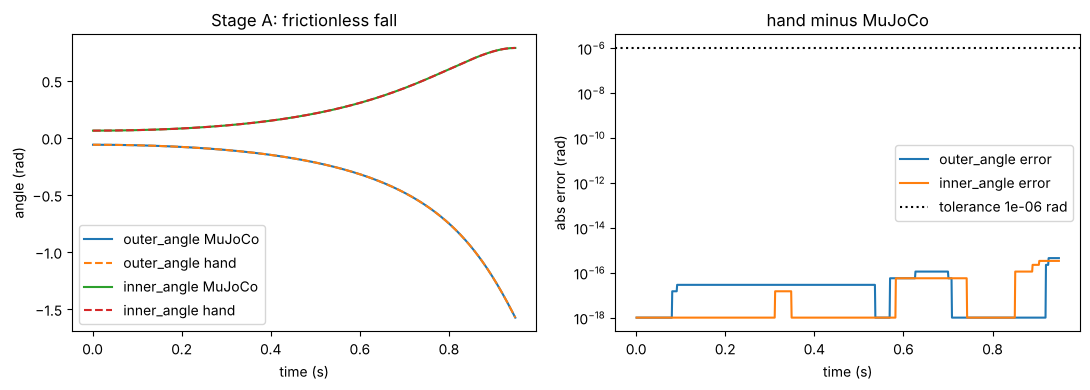

saved the data


In [9]:
# ─────────────────────────────────────────────
# STEP 8: run the frictionless fall and compare with MuJoCo
# What we have: start_angles, start_rates (5 and 45 degrees, at rest), motors off, no friction
# What we want: hand and MuJoCo trajectories until the tip passes horizontal, and their difference
# Why: this is the pass test of stage A: max abs angle error <= 1e-6 rad
# ─────────────────────────────────────────────

TOLERANCE_RAD = 1e-6  # fixed before looking
MAX_STEPS = 30000

hand_result = simulate(start_angles, start_rates, MAX_STEPS, stop_below_horizontal=True)
mujoco_result = run_mujoco(start_angles, MAX_STEPS, stop_below_horizontal=True)  # damping 0, frictionloss 0
angle_error = compare_angles(hand_result, mujoco_result, TOLERANCE_RAD, "stage A")

hand_energy_drift = np.abs(hand_result["energy"] - hand_result["energy"][0]).max()
mujoco_energy_drift = np.abs(mujoco_result["energy"] - mujoco_result["energy"][0]).max()
print(f"fall time = {len(angle_error) * time_step:.3f} s")
print(f"energy drift: hand = {hand_energy_drift:.2e} J, MuJoCo = {mujoco_energy_drift:.2e} J")

plot_overlay(hand_result, mujoco_result, angle_error, TOLERANCE_RAD, "Stage A: frictionless fall", "stage_a_overlay")
np.savez(os.path.join(RESULT_DIR, f"hand_stage_a_{TIMESTAMP}.npz"),
         angles=hand_result["angles"], rates=hand_result["rates"], energy=hand_result["energy"])
print("saved the data")
